In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

VARIANT = 1
np.random.seed(VARIANT)
city = "Київ"
monthly_temp = [-4, -3, 2, 9, 15, 19, 21, 20, 14, 8, 2, -2]
months = ["Січ", "Лют", "Бер", "Кві", "Тра", "Чер", 
          "Лип", "Сер", "Вер", "Жов", "Лис", "Гру"]

rows = []
for month, temp in zip(months, monthly_temp):
    heating_days = np.clip(18 - temp + np.random.normal(0, 1.5), 0, 30)
    heating_days = round(heating_days)
    cost = 0.15 * heating_days + np.random.normal(0, 1.0)
    cost = round(max(cost, 0), 1)
    rows.append({
        "місто": city, "місяць": month, "температура": temp,
        "опалювальні_дні": heating_days, "витрати_на_опалення": cost,
    })

climate = pd.DataFrame(rows)
print("Перші 5 рядків згенерованого набору:")
print(climate.head())

Перші 5 рядків згенерованого набору:
  місто місяць  температура  опалювальні_дні  витрати_на_опалення
0  Київ    Січ           -4               24                  3.0
1  Київ    Лют           -3               20                  1.9
2  Київ    Бер            2               17                  0.2
3  Київ    Кві            9               12                  1.0
4  Київ    Тра           15                3                  0.2


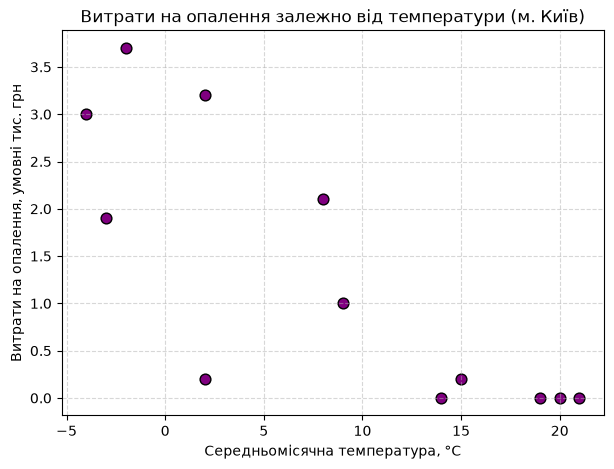

In [2]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(climate["температура"], climate["витрати_на_опалення"], color="purple", s=60, edgecolor="black")
ax.set_xlabel("Середньомісячна температура, °C")
ax.set_ylabel("Витрати на опалення, умовні тис. грн")
ax.set_title("Витрати на опалення залежно від температури (м. Київ)")
ax.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [3]:
r_res = pearsonr(climate["температура"], climate["витрати_на_опалення"])
rho_res = spearmanr(climate["температура"], climate["витрати_на_опалення"])

r_val, p_val_r = r_res.statistic, r_res.pvalue
rho_val, p_val_rho = rho_res.statistic, rho_res.pvalue

print(f"Пірсон:  r = {r_val:.4f}, p-value = {p_val_r:.4e}")
print(f"Спірмен: rho = {rho_val:.4f}, p-value = {p_val_rho:.4e}")

# 95% довірчий інтервал для Пірсона
ci_r = r_res.confidence_interval(confidence_level=0.95)
print(f"95% довірчий інтервал для r: ({ci_r.low:.4f}, {ci_r.high:.4f})")

Пірсон:  r = -0.8065, p-value = 1.5285e-03
Спірмен: rho = -0.8269, p-value = 9.0770e-04
95% довірчий інтервал для r: (-0.9436, -0.4330)


In [4]:
vars_df = climate[["температура", "опалювальні_дні", "витрати_на_опалення"]]

corr_pearson = vars_df.corr(method="pearson")
print("--- Кореляційна матриця Пірсона ---")
print(corr_pearson.round(3))

corr_spearman = vars_df.corr(method="spearman")
print("\n--- Кореляційна матриця Спірмена ---")
print(corr_spearman.round(3))

--- Кореляційна матриця Пірсона ---
                     температура  опалювальні_дні  витрати_на_опалення
температура                1.000           -0.987               -0.806
опалювальні_дні           -0.987            1.000                0.787
витрати_на_опалення       -0.806            0.787                1.000

--- Кореляційна матриця Спірмена ---
                     температура  опалювальні_дні  витрати_на_опалення
температура                1.000           -0.982               -0.827
опалювальні_дні           -0.982            1.000                0.822
витрати_на_опалення       -0.827            0.822                1.000


In [5]:
climate_corrupted = climate.copy()
# Штучно збільшуємо витрати в липні в 5 разів (аварія на котельні)
climate_corrupted.loc[climate_corrupted["місяць"] == "Лип", "витрати_на_опалення"] *= 5.0

r_corr = pearsonr(climate_corrupted["температура"], climate_corrupted["витрати_на_опалення"])
rho_corr = spearmanr(climate_corrupted["температура"], climate_corrupted["витрати_на_опалення"])

print(f"З аномалією — Пірсон r:  {r_corr.statistic:.4f}")
print(f"З аномалією — Спірмен rho: {rho_corr.statistic:.4f}")

З аномалією — Пірсон r:  -0.8065
З аномалією — Спірмен rho: -0.8269
